
..DATASET INFO..

Dataset Shape:
(42, 9)

Columns:
Index(['Anode', 'Cathode', 'SE', 'Coating', 'Testing temp.[°C]', 'Rate',
       'Current Density', 'Discharge Capacity in 1st Cycle',
       'Charge Capacity in 1st cycle'],
      dtype='object')

Missing Values:
Anode                              0
Cathode                            0
SE                                 0
Coating                            0
Testing temp.[°C]                  0
Rate                               0
Current Density                    0
Discharge Capacity in 1st Cycle    0
Charge Capacity in 1st cycle       0
dtype: int64

Dataset Shape After Cleaning:
(42, 9)

Dataset Shape After Outlier Removal:
(37, 9)

..FIRST 5 ROWS AFTER TARGET ENCODING..

        Anode     Cathode          SE     Coating  Testing temp.[°C]    Rate  \
0  138.672778  141.860448  138.605284  139.941566              100.0  18.000   
1  142.919046  141.860448  140.665127  140.801143               25.0   0.100   
2  142.919046  141.8604

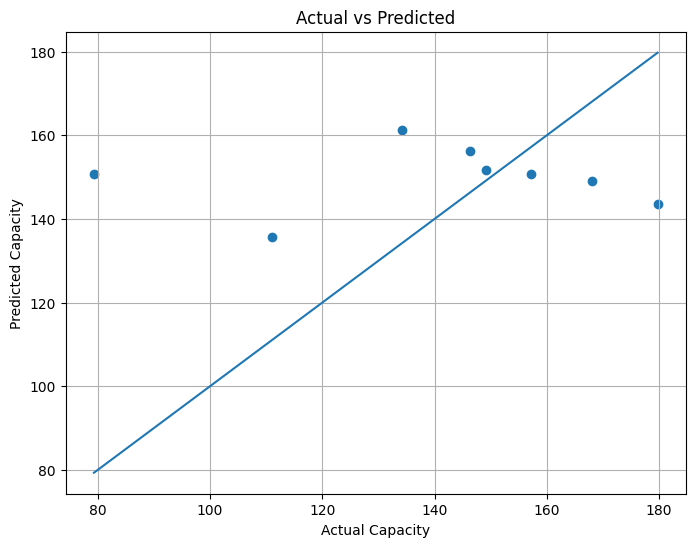


..FEATURE IMPORTANCE..

                      Feature  Importance
2                     cat__SE    0.505019
1                cat__Cathode    0.155915
5                   num__Rate    0.097600
8     num__Current_Rate_Ratio    0.070440
4      num__Testing temp.[°C]    0.056050
3                cat__Coating    0.055597
7  num__Temp_Rate_Interaction    0.033467
6        num__Current Density    0.016955
0                  cat__Anode    0.008958


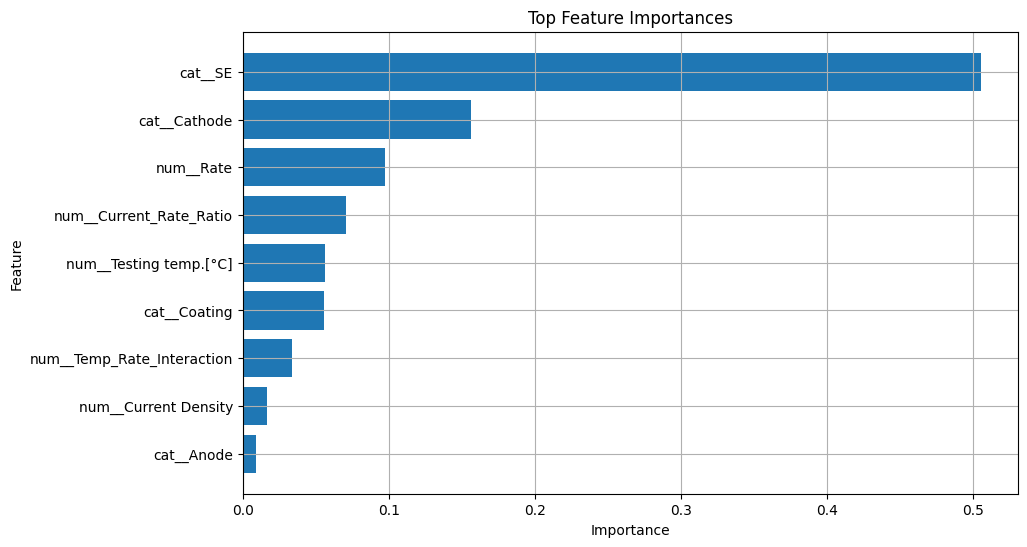


..SHAP ANALYSIS..



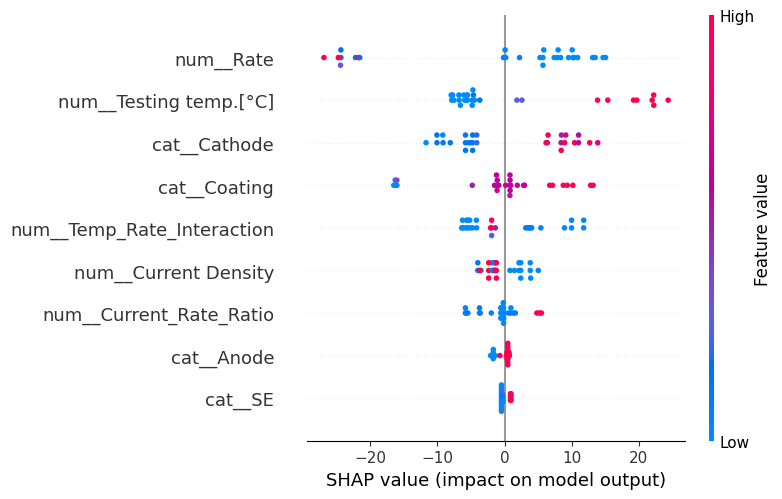


..PARTIAL DEPENDENCE PLOTS..



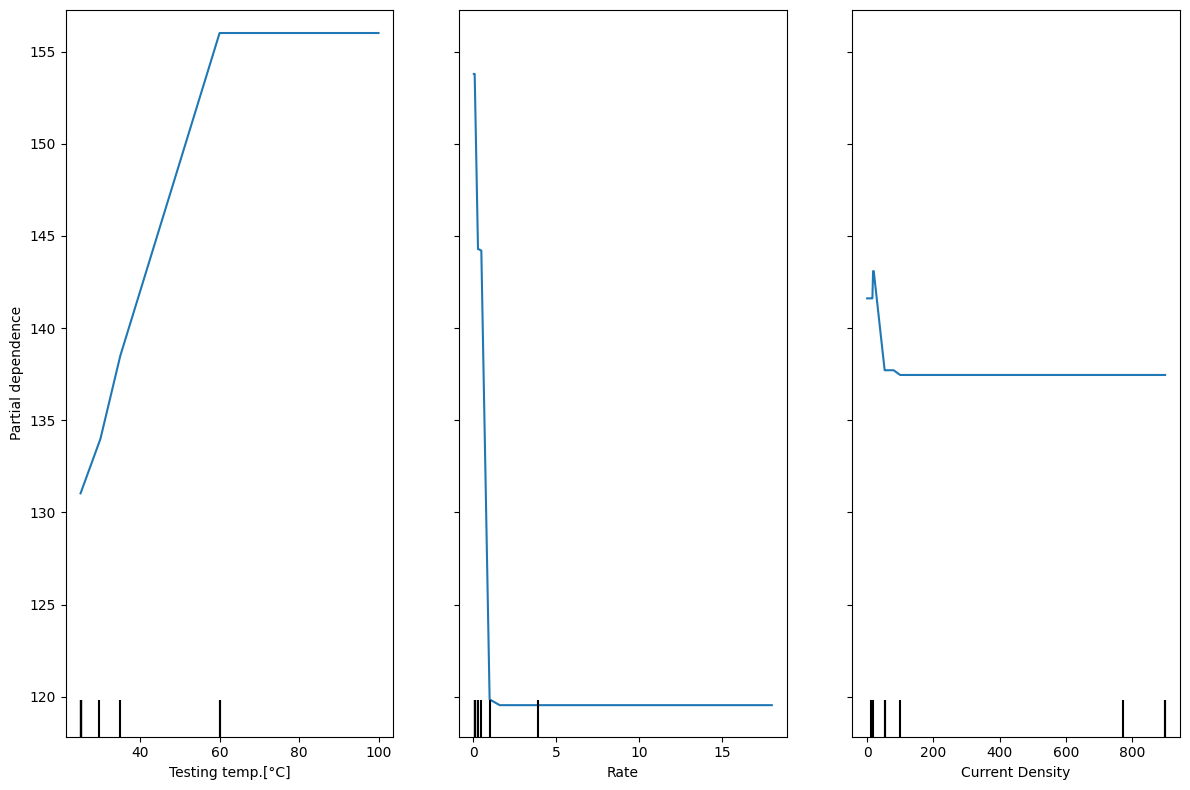


Model Saved Successfully!


In [ ]:
# 1. IMPORT LIBRARIES
!pip install category_encoders
!pip install shap
!pip install xgboost
!pip install openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    LeaveOneOut,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from category_encoders import TargetEncoder

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import (
    PartialDependenceDisplay
)

from xgboost import XGBRegressor

# 2. LOAD DATASET
df = pd.read_excel("/content/term project dataset.xlsx")

# 3. BASIC DATA CLEANING
print("\n..DATASET INFO..\n")

print("Dataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

# Remove duplicates
df = df.drop_duplicates()

# Remove missing values
df = df.dropna()

print("\nDataset Shape After Cleaning:")
print(df.shape)

# REMOVE OUTLIERS FROM TARGET
TARGET = "Discharge Capacity in 1st Cycle"

Q1 = df[TARGET].quantile(0.25)
Q3 = df[TARGET].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[
    (df[TARGET] >= lower_bound) &
    (df[TARGET] <= upper_bound)
]

print("\nDataset Shape After Outlier Removal:")
print(df.shape)

# 4. DEFINE TARGET
TARGET = "Discharge Capacity in 1st Cycle"

# FEATURE ENGINEERING
df["Temp_Rate_Interaction"] = (
    df["Testing temp.[°C]"] *
    df["Rate"]
)

df["Current_Rate_Ratio"] = (
    df["Current Density"] /
    (df["Rate"] + 1e-6)
)

# 5. DEFINE FEATURES
X = df[[
    "Anode",
    "Cathode",
    "SE",
    "Coating",
    "Testing temp.[°C]",
    "Rate",
    "Current Density",
    "Temp_Rate_Interaction",
    "Current_Rate_Ratio"
]]

y = df[TARGET]

# 6. DEFINE COLUMN TYPES
categorical_cols = [
    "Anode",
    "Cathode",
    "SE",
    "Coating"
]

numerical_cols = [
    "Testing temp.[°C]",
    "Rate",
    "Current Density",
    "Temp_Rate_Interaction",
    "Current_Rate_Ratio"
]

# 7. PREPROCESSING
preprocessor = ColumnTransformer(
    transformers=[
       (
    "cat",
    TargetEncoder(),
    categorical_cols
),
        (
            "num",
            "passthrough",
            numerical_cols
        )
    ]
)

# VIEW FIRST 5 ROWS AFTER TARGET ENCODING
# Fit and transform the features
X_encoded = preprocessor.fit_transform(X, y)
# Convert to DataFrame
encoded_feature_names = categorical_cols + numerical_cols

X_encoded_df = pd.DataFrame(
    X_encoded,
    columns=encoded_feature_names
)

print("\n..FIRST 5 ROWS AFTER TARGET ENCODING..\n")
print(X_encoded_df.head())

# 8. DEFINE IMPROVED XGBOOST MODEL
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.01,
    reg_lambda=3,
    random_state=42
)

# 9. CREATE PIPELINE
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("xgboost", xgb_model)
])

# 10. STRATIFIED TRAIN TEST SPLIT
# Create bins for stratified regression split
df["target_bins"] = pd.qcut(
    y,
    q=5,
    labels=False,
    duplicates="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df["target_bins"]
)

print("\n..TRAIN TEST SPLIT..\n")

print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))

# 11. HYPERPARAMETER TUNING
print("\n..HYPERPARAMETER TUNING..\n")

param_grid = {

    "xgboost__max_depth": [3, 5, 7],

    "xgboost__learning_rate": [0.01, 0.03, 0.05],

    "xgboost__min_child_weight": [1, 3, 5],

    "xgboost__subsample": [0.7, 0.8, 1.0],

    "xgboost__colsample_bytree": [0.7, 0.8, 1.0],

    "xgboost__gamma": [0, 0.1, 0.3],

    "xgboost__reg_alpha": [0, 0.01, 0.1],

    "xgboost__reg_lambda": [1, 3, 5]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV Score:")
print(grid_search.best_score_)

# Assign the best estimator to best_model
best_model = grid_search.best_estimator_

# 12. BEST MODEL
# Get the fitted preprocessor from the best_model pipeline
preprocessor_fitted = best_model.named_steps['preprocessor']

# Transform X_test using the fitted preprocessor
X_test_transformed = preprocessor_fitted.transform(X_test)

best_model.fit(
    X_train,
    y_train,
    xgboost__eval_set=[(X_test_transformed, y_test)], # Use transformed X_test
    xgboost__verbose=False
)

print("\nFinal Model Training Completed")

# 14. PREDICTIONS

y_train_pred = best_model.predict(X_train)

y_test_pred = best_model.predict(X_test)

# DETECT BATTERY WITH BEST DISCHARGE CAPACITY
# Create results dataframe
battery_results = X.copy()

battery_results["Actual_Discharge_Capacity"] = y.values

battery_results["Predicted_Discharge_Capacity"] = best_model.predict(X)

# Sort by predicted discharge capacity
best_batteries = battery_results.sort_values(
    by="Predicted_Discharge_Capacity",
    ascending=False
)

print("\n..TOP 10 BATTERIES WITH BEST DISCHARGE CAPACITY..\n")

print(best_batteries.head(10))

# 15. TRAINING METRICS
train_r2 = r2_score(y_train, y_train_pred)

train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

train_mae = mean_absolute_error(
    y_train,
    y_train_pred
)

print("\n..TRAINING PERFORMANCE..\n")

print(f"Train R²   : {train_r2:.4f}")
print(f"Train RMSE : {train_rmse:.4f}")
print(f"Train MAE  : {train_mae:.4f}")

# 16. TEST METRICS
test_r2 = r2_score(y_test, y_test_pred)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred)
)

test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

print("\n..TEST PERFORMANCE..\n")

print(f"Test R²   : {test_r2:.4f}")
print(f"Test RMSE : {test_rmse:.4f}")
print(f"Test MAE  : {test_mae:.4f}")

# 17. K-FOLD CROSS VALIDATION
print("\n..K-FOLD CROSS VALIDATION..\n")

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_model,
    X,
    y,
    cv=kfold,
    scoring="r2"
)

print("K-Fold CV Scores:")
print(cv_scores)

print("\nAverage K-Fold R²:")
print(cv_scores.mean())

# 18, a. LOOCV USING MAE AND RMSE
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

loo = LeaveOneOut()

actual_values = []
predicted_values = []

for train_index, test_index in loo.split(X):

    X_train_loo = X.iloc[train_index]
    X_test_loo = X.iloc[test_index]

    y_train_loo = y.iloc[train_index]
    y_test_loo = y.iloc[test_index]

    # Train model
    best_model.fit(X_train_loo, y_train_loo)

    # Predict
    prediction = best_model.predict(X_test_loo)

    actual_values.append(y_test_loo.values[0])
    predicted_values.append(prediction[0])

# 18. b. LOOCV METRICS
loo_mae = mean_absolute_error(
    actual_values,
    predicted_values
)

loo_rmse = np.sqrt(
    mean_squared_error(
        actual_values,
        predicted_values
    )
)

loo_r2 = r2_score(
    actual_values,
    predicted_values
)

print("\n..LOOCV RESULTS..\n")

print(f"LOOCV MAE  : {loo_mae:.4f}")
print(f"LOOCV RMSE : {loo_rmse:.4f}")
print(f"LOOCV R²   : {loo_r2:.4f}")

# 19. ACTUAL VS PREDICTED TABLE
results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred
})

print("\n..ACTUAL VS PREDICTED..\n")
print(results_df)

# 20. ACTUAL VS PREDICTED PLOT
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred)

min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Actual Capacity")
plt.ylabel("Predicted Capacity")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.show()

# 21. FEATURE IMPORTANCE
print("\n..FEATURE IMPORTANCE..\n")

# Get transformed feature names
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importance_scores = best_model.named_steps[
    "xgboost"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

# 22. FEATURE IMPORTANCE PLOT

top_n = 15

top_features = importance_df.head(top_n)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title("Top Feature Importances")

plt.gca().invert_yaxis()

plt.grid(True)

plt.show()

# 23. SHAP ANALYSIS
print("\n..SHAP ANALYSIS..\n")

# Transform data
X_train_transformed = best_model.named_steps[
    "preprocessor"
].transform(X_train)

# Extract trained XGBoost model
trained_xgb = best_model.named_steps["xgboost"]

# SHAP explainer
explainer = shap.Explainer(
    trained_xgb
)

# Calculate SHAP values
shap_values = explainer(
    X_train_transformed
)

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_train_transformed,
    feature_names=feature_names
)

# 24. PARTIAL DEPENDENCE PLOTS
print("\n..PARTIAL DEPENDENCE PLOTS..\n")
# Features to visualize
features_to_plot = [
    "Testing temp.[°C]",
    "Rate",
    "Current Density"
]

fig, ax = plt.subplots(
    figsize=(12, 8)
)

PartialDependenceDisplay.from_estimator(
    best_model,
    X_train,
    features_to_plot,
    ax=ax
)

plt.tight_layout()

plt.show()

# 25. SAVE MODEL
joblib.dump(
    best_model,
    "battery_xgboost_model.json"
)

print("\nModel Saved Successfully!")